# Synergy Analysis — Ambulance + Facility Pooling

Is sharing both better than the best individual policy?
Cherry-pick scenarios that demonstrate the mechanism.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster" / "sobol_no_t2_fixed_pooling" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
OUTCOME = "death_rate_T1_BCAS"

stove = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
amb   = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
fac   = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
both  = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)

assert (stove["scenario"].values == amb["scenario"].values).all()
assert (stove["scenario"].values == fac["scenario"].values).all()
assert (stove["scenario"].values == both["scenario"].values).all()

m = stove[UNCERTAINTIES].copy()
m["mort_stove"] = stove[OUTCOME].values
m["mort_amb"]   = amb[OUTCOME].values
m["mort_fac"]   = fac[OUTCOME].values
m["mort_both"]  = both[OUTCOME].values

m["delta_amb"]  = m["mort_amb"]  - m["mort_stove"]
m["delta_fac"]  = m["mort_fac"]  - m["mort_stove"]
m["delta_both"] = m["mort_both"] - m["mort_stove"]
m["best_individual"] = np.minimum(m["delta_amb"], m["delta_fac"])
m["synergy"] = m["delta_both"] - m["best_individual"]

print(f"Scenarios: {len(m)}")
print(f"Synergy range: {m['synergy'].min():.4f} to {m['synergy'].max():.4f}")
print(f"Synergy < -0.01 (complementary): {(m['synergy'] < -0.01).sum()} ({(m['synergy'] < -0.01).mean():.1%})")
print(f"Synergy ~0 (no interaction): {((m['synergy'] >= -0.01) & (m['synergy'] <= 0.01)).sum()}")
print(f"Synergy > 0.01 (interference): {(m['synergy'] > 0.01).sum()} ({(m['synergy'] > 0.01).mean():.1%})")

Loaded 98304 runs
Scenarios: 24576
Synergy range: -0.6667 to 0.5000
Synergy < -0.01 (complementary): 6398 (26.0%)
Synergy ~0 (no interaction): 16596
Synergy > 0.01 (interference): 1582 (6.4%)


## Synergy Distribution

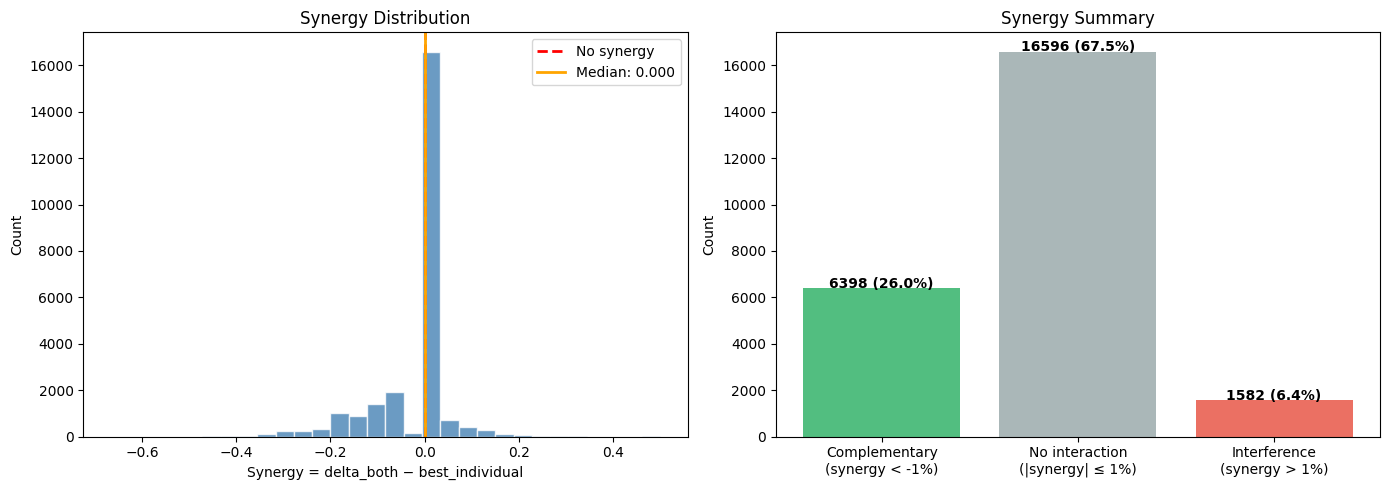

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(m["synergy"], bins=30, color="steelblue", alpha=0.8, edgecolor="white")
axes[0].axvline(0, color="red", linewidth=2, linestyle="--", label="No synergy")
axes[0].axvline(m["synergy"].median(), color="orange", linewidth=2, label=f"Median: {m['synergy'].median():.3f}")
axes[0].set_xlabel("Synergy = delta_both − best_individual")
axes[0].set_ylabel("Count")
axes[0].set_title("Synergy Distribution")
axes[0].legend()

n_comp = (m["synergy"] < -0.01).sum()
n_neut = ((m["synergy"] >= -0.01) & (m["synergy"] <= 0.01)).sum()
n_int  = (m["synergy"] > 0.01).sum()
bars = axes[1].bar(["Complementary\n(synergy < -1%)", "No interaction\n(|synergy| ≤ 1%)", "Interference\n(synergy > 1%)"],
                    [n_comp, n_neut, n_int],
                    color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_comp, n_neut, n_int]):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f"{val} ({val/len(m):.1%})", ha="center", fontweight="bold")
axes[1].set_ylabel("Count")
axes[1].set_title("Synergy Summary")

plt.tight_layout()
plt.show()

## Four-Policy Comparison — All Scenarios

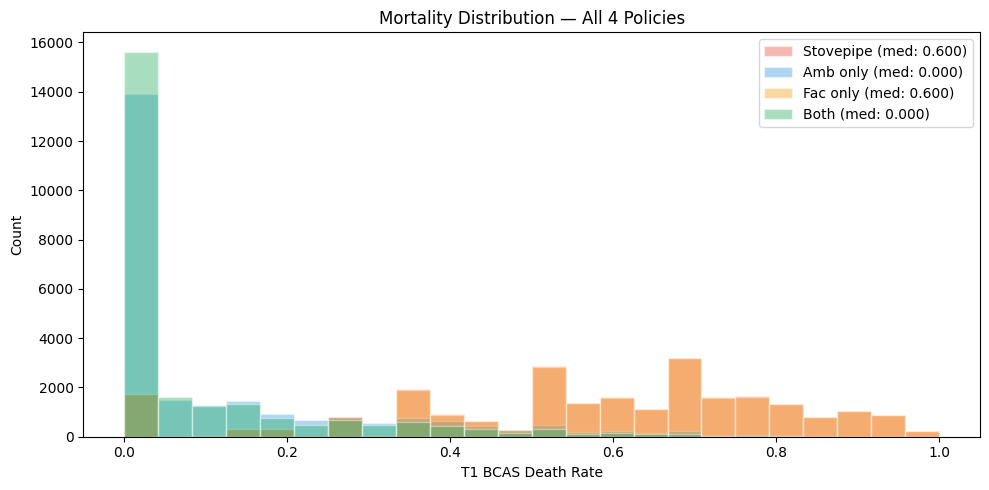

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, 1, 25)
colors = ["#e74c3c", "#3498db", "#f39c12", "#27ae60"]
labels_pol = ["Stovepipe", "Amb only", "Fac only", "Both"]
for vals, col, lab in zip([m["mort_stove"], m["mort_amb"], m["mort_fac"], m["mort_both"]], colors, labels_pol):
    ax.hist(vals, bins=bins, alpha=0.4, color=col, edgecolor="white", label=f"{lab} (med: {vals.median():.3f})")
ax.set_xlabel("T1 BCAS Death Rate")
ax.set_ylabel("Count")
ax.set_title("Mortality Distribution — All 4 Policies")
ax.legend()
plt.tight_layout()
plt.show()

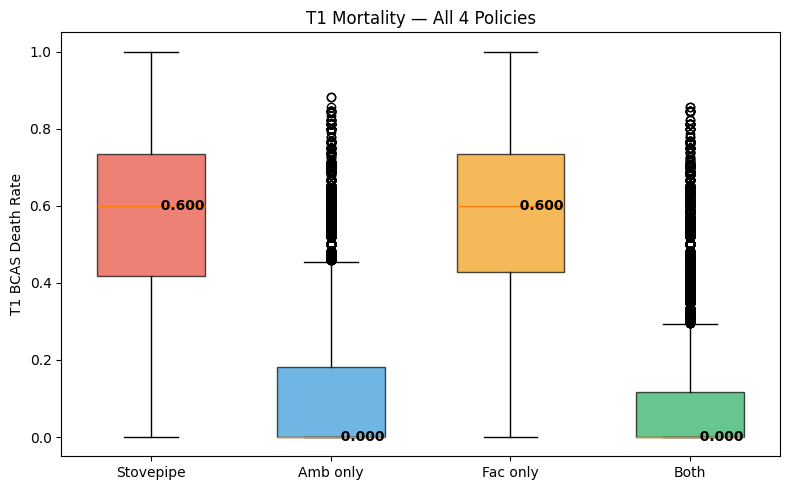

Stovepipe: median=0.600, mean=0.564, nonzero=22849/24576 (93.0%)
Amb only: median=0.000, mean=0.114, nonzero=10690/24576 (43.5%)
Fac only: median=0.600, mean=0.566, nonzero=22862/24576 (93.0%)
Both: median=0.000, mean=0.085, nonzero=8994/24576 (36.6%)


In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

data = [m["mort_stove"].values, m["mort_amb"].values, m["mort_fac"].values, m["mort_both"].values]
labels = ["Stovepipe", "Amb only", "Fac only", "Both"]
colors = ["#e74c3c", "#3498db", "#f39c12", "#27ae60"]

bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, widths=0.6)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data):
    med = np.median(d)
    ax.text(i + 1, med, f"  {med:.3f}", va="center", fontsize=10, fontweight="bold")

ax.set_ylabel("T1 BCAS Death Rate")
ax.set_title("T1 Mortality — All 4 Policies")
plt.tight_layout()
plt.show()

for label, d in zip(labels, data):
    nz = (d > 0).sum()
    print(f"{label}: median={np.median(d):.3f}, mean={np.mean(d):.3f}, nonzero={nz}/{len(d)} ({nz/len(d):.1%})")

## PRIM — Where does synergy occur?

Complementary cases: 6398 / 24576 (26.0%)



Box where both > best individual:
coverage       0.163176
density        0.808675
id            26.000000
k           1044.000000
mass           0.052531
mean           0.808675
n           1291.000000
res_dim        4.000000
Name: 26, dtype: float64

                       box 26                                        
                          min        max      qp value       qp value
waves_per_day        1.000000   1.500000           NaN  7.559374e-115
ccp_r1_same_bn_min  10.000000  19.500000           NaN   1.819986e-02
wave_duration_min    1.000000  42.500000           NaN   6.028221e-02
bcas_rate            0.040746   0.069995  7.188669e-73            NaN



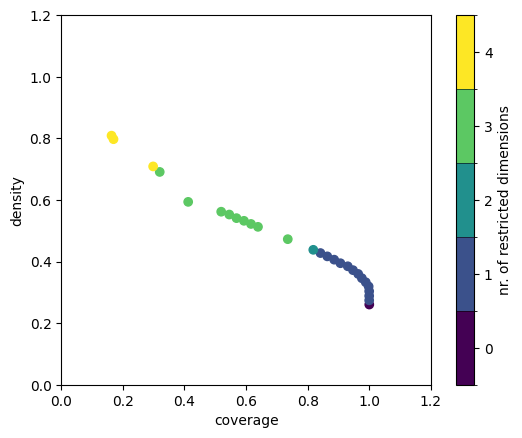

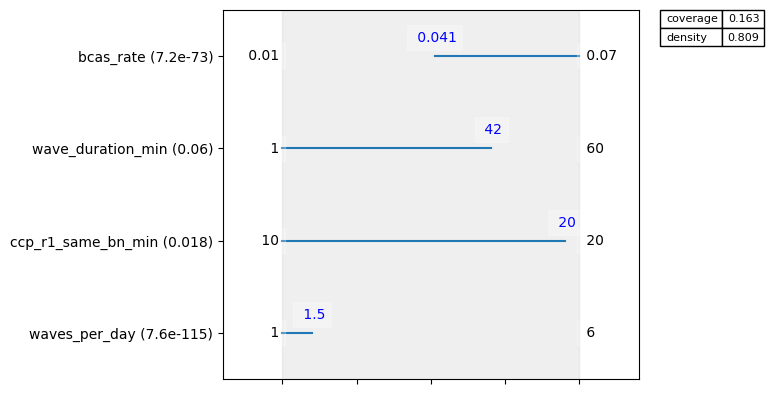

In [5]:
from ema_workbench.analysis import prim

x = m[UNCERTAINTIES].astype(float)
y_synergy = m["synergy"].values < -0.01

print(f"Complementary cases: {y_synergy.sum()} / {len(y_synergy)} ({y_synergy.mean():.1%})")

if y_synergy.sum() >= 10:
    p = prim.Prim(x, y_synergy, threshold=0.5)
    box = p.find_box()
    box.show_tradeoff()
    print("\nBox where both > best individual:")
    box.inspect(style="graph")
    box.inspect()
else:
    print("Too few cases for PRIM.")

## Cherry-Picked Scenarios for Replay

Find scenarios that clearly demonstrate the synergy mechanism:
1. A scenario where amb helps, fac doesn't, but both helps even more than amb alone
2. Show the parameters for replay

In [6]:
# ── Scenario A: Strong synergy (both >> amb >> stove, fac neutral) ─────────
synergy_scenarios = m[(m["synergy"] < -0.05) & (m["delta_amb"] < -0.1) & (m["delta_fac"] > -0.05)].copy()
synergy_scenarios = synergy_scenarios.sort_values("synergy")

if len(synergy_scenarios) > 0:
    best = synergy_scenarios.iloc[0]
    print("SCENARIO A — Strong synergy (amb helps, fac neutral, both even better):")
    print(f"  Row index: {best.name}")
    for c in UNCERTAINTIES:
        print(f"  {c}: {best[c]}")
    print(f"  Stovepipe: {best['mort_stove']:.4f}")
    print(f"  Amb only:  {best['mort_amb']:.4f}  (delta: {best['delta_amb']:.4f})")
    print(f"  Fac only:  {best['mort_fac']:.4f}  (delta: {best['delta_fac']:.4f})")
    print(f"  Both:      {best['mort_both']:.4f}  (delta: {best['delta_both']:.4f})")
    print(f"  Synergy:   {best['synergy']:.4f}")
else:
    print("No strong synergy scenarios found with amb helping and fac neutral.")

# ── Scenario B: No synergy baseline (amb helps, both = amb) ────────────────
no_synergy = m[(m["delta_amb"] < -0.1) & (m["synergy"].abs() < 0.01) & (m["mort_stove"] > 0.2)].copy()
no_synergy = no_synergy.sort_values("delta_amb")

if len(no_synergy) > 0:
    baseline = no_synergy.iloc[0]
    print(f"\nSCENARIO B — No synergy baseline (amb helps, both = amb):")
    print(f"  Row index: {baseline.name}")
    for c in UNCERTAINTIES:
        print(f"  {c}: {baseline[c]}")
    print(f"  Stovepipe: {baseline['mort_stove']:.4f}")
    print(f"  Amb only:  {baseline['mort_amb']:.4f}  (delta: {baseline['delta_amb']:.4f})")
    print(f"  Fac only:  {baseline['mort_fac']:.4f}  (delta: {baseline['delta_fac']:.4f})")
    print(f"  Both:      {baseline['mort_both']:.4f}  (delta: {baseline['delta_both']:.4f})")
    print(f"  Synergy:   {baseline['synergy']:.4f}")
else:
    print("No baseline scenario found.")

SCENARIO A — Strong synergy (amb helps, fac neutral, both even better):
  Row index: 20892
  ccp_r1_same_bn_min: 14.0
  ccp_r1_inter_bn_min: 18.0
  bcas_rate: 0.0422409236617386
  waves_per_day: 1.0
  wave_duration_min: 13.0
  Stovepipe: 0.8571
  Amb only:  0.5714  (delta: -0.2857)
  Fac only:  0.8571  (delta: 0.0000)
  Both:      0.0000  (delta: -0.8571)
  Synergy:   -0.5714

SCENARIO B — No synergy baseline (amb helps, both = amb):
  Row index: 15825
  ccp_r1_same_bn_min: 10.0
  ccp_r1_inter_bn_min: 35.0
  bcas_rate: 0.0233791808784008
  waves_per_day: 4.0
  wave_duration_min: 20.0
  Stovepipe: 1.0000
  Amb only:  0.0000  (delta: -1.0000)
  Fac only:  1.0000  (delta: 0.0000)
  Both:      0.0000  (delta: -1.0000)
  Synergy:   0.0000


## Visual: 4-Policy Bar Chart for Cherry-Picked Scenarios

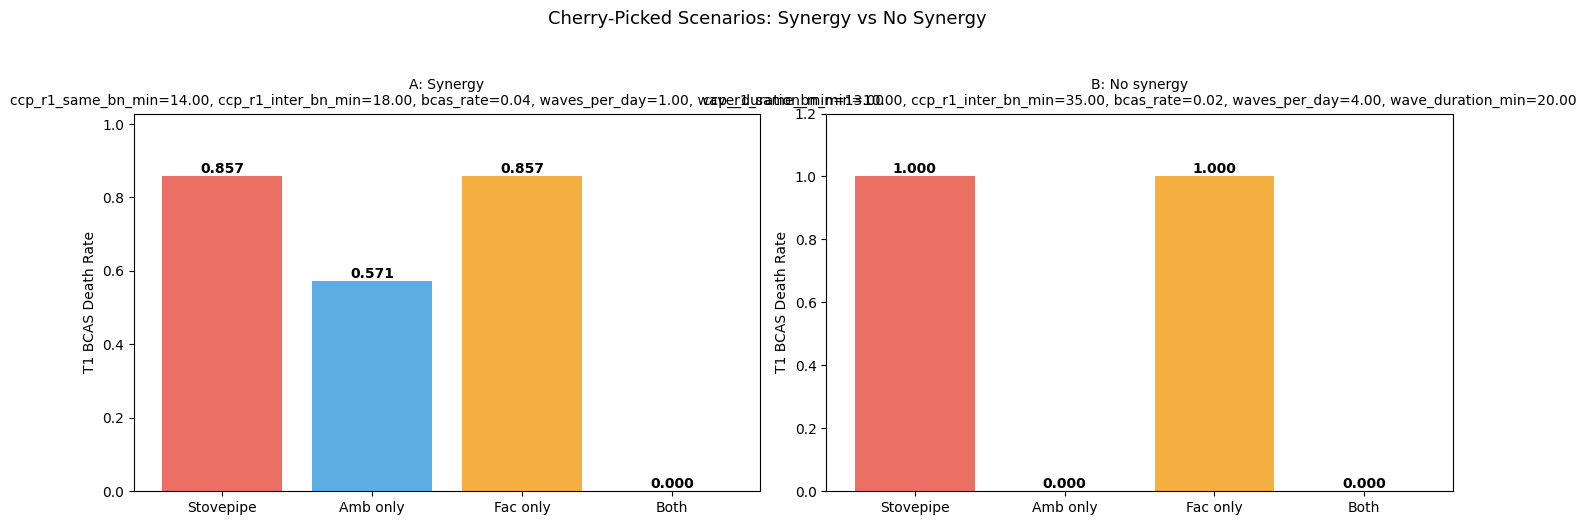

In [7]:
scenarios_to_plot = []
if len(synergy_scenarios) > 0:
    scenarios_to_plot.append(("A: Synergy", synergy_scenarios.iloc[0]))
if len(no_synergy) > 0:
    scenarios_to_plot.append(("B: No synergy", no_synergy.iloc[0]))

if scenarios_to_plot:
    fig, axes = plt.subplots(1, len(scenarios_to_plot), figsize=(7 * len(scenarios_to_plot), 5))
    if len(scenarios_to_plot) == 1:
        axes = [axes]

    for ax, (title, row) in zip(axes, scenarios_to_plot):
        vals = [row["mort_stove"], row["mort_amb"], row["mort_fac"], row["mort_both"]]
        colors = ["#e74c3c", "#3498db", "#f39c12", "#27ae60"]
        labels = ["Stovepipe", "Amb only", "Fac only", "Both"]
        bars = ax.bar(labels, vals, color=colors, alpha=0.8)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                     f"{val:.3f}", ha="center", fontweight="bold")
        ax.set_ylabel("T1 BCAS Death Rate")
        ax.set_ylim(0, max(vals) * 1.2)
        param_str = ", ".join(f"{c}={row[c]:.2f}" if isinstance(row[c], float) else f"{c}={int(row[c])}" for c in UNCERTAINTIES)
        ax.set_title(f"{title}\n{param_str}", fontsize=10)

    fig.suptitle("Cherry-Picked Scenarios: Synergy vs No Synergy", fontsize=13, y=1.04)
    plt.tight_layout()
    plt.show()
else:
    print("No scenarios to plot.")

## Replay Commands

In [8]:
print("To replay these scenarios, use replay_run() with the stovepipe scenario")
print("and manually set the eligibility levers for each policy.")
print()
for label, scenarios in [("Synergy", synergy_scenarios), ("No synergy", no_synergy)]:
    if len(scenarios) > 0:
        row = scenarios.iloc[0]
        print(f"\n── {label} (row {row.name}) ──")
        print(f"  Parameters:")
        for c in UNCERTAINTIES:
            print(f"    {c}: {row[c]}")
        print(f"  Run 4 times with:")
        print(f"    Stovepipe: fac=0, amb=0  → mort={row['mort_stove']:.4f}")
        print(f"    Amb only:  fac=0, amb=1  → mort={row['mort_amb']:.4f}")
        print(f"    Fac only:  fac=1, amb=0  → mort={row['mort_fac']:.4f}")
        print(f"    Both:      fac=1, amb=1  → mort={row['mort_both']:.4f}")

To replay these scenarios, use replay_run() with the stovepipe scenario
and manually set the eligibility levers for each policy.


── Synergy (row 20892) ──
  Parameters:
    ccp_r1_same_bn_min: 14.0
    ccp_r1_inter_bn_min: 18.0
    bcas_rate: 0.0422409236617386
    waves_per_day: 1.0
    wave_duration_min: 13.0
  Run 4 times with:
    Stovepipe: fac=0, amb=0  → mort=0.8571
    Amb only:  fac=0, amb=1  → mort=0.5714
    Fac only:  fac=1, amb=0  → mort=0.8571
    Both:      fac=1, amb=1  → mort=0.0000

── No synergy (row 15825) ──
  Parameters:
    ccp_r1_same_bn_min: 10.0
    ccp_r1_inter_bn_min: 35.0
    bcas_rate: 0.0233791808784008
    waves_per_day: 4.0
    wave_duration_min: 20.0
  Run 4 times with:
    Stovepipe: fac=0, amb=0  → mort=1.0000
    Amb only:  fac=0, amb=1  → mort=0.0000
    Fac only:  fac=1, amb=0  → mort=1.0000
    Both:      fac=1, amb=1  → mort=0.0000


## Decision Tree — When is ambulance alone better than both?

PRIM couldn't find a box where both is worse. A decision tree can capture non-linear splits.

Amb alone better than both: 1541 / 24576 (6.3%)
Both better or equal: 23035 (93.7%)



Decision Tree depth=3
CV accuracy: 0.937 ± 0.000

Classification report:
              precision    recall  f1-score   support

  Both ≥ Amb       0.94      1.00      0.97     23035
  Amb better       0.00      0.00      0.00      1541

    accuracy                           0.94     24576
   macro avg       0.47      0.50      0.48     24576
weighted avg       0.88      0.94      0.91     24576



C:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif

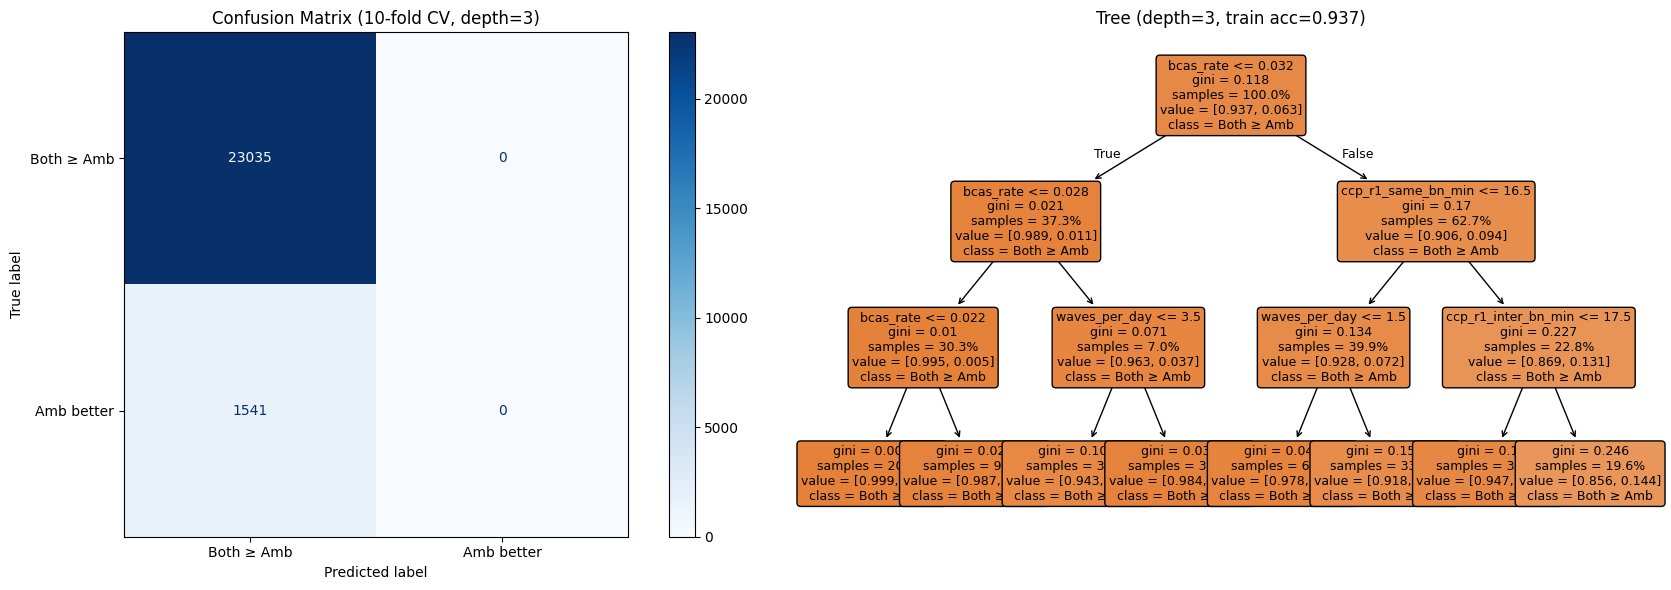

Feature importance:
bcas_rate             0.6356
ccp_r1_same_bn_min    0.1874
waves_per_day         0.0892
ccp_r1_inter_bn_min   0.0878
wave_duration_min     0.0000




Decision Tree depth=4
CV accuracy: 0.937 ± 0.000

Classification report:
              precision    recall  f1-score   support

  Both ≥ Amb       0.94      1.00      0.97     23035
  Amb better       0.00      0.00      0.00      1541

    accuracy                           0.94     24576
   macro avg       0.47      0.50      0.48     24576
weighted avg       0.88      0.94      0.91     24576



C:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif

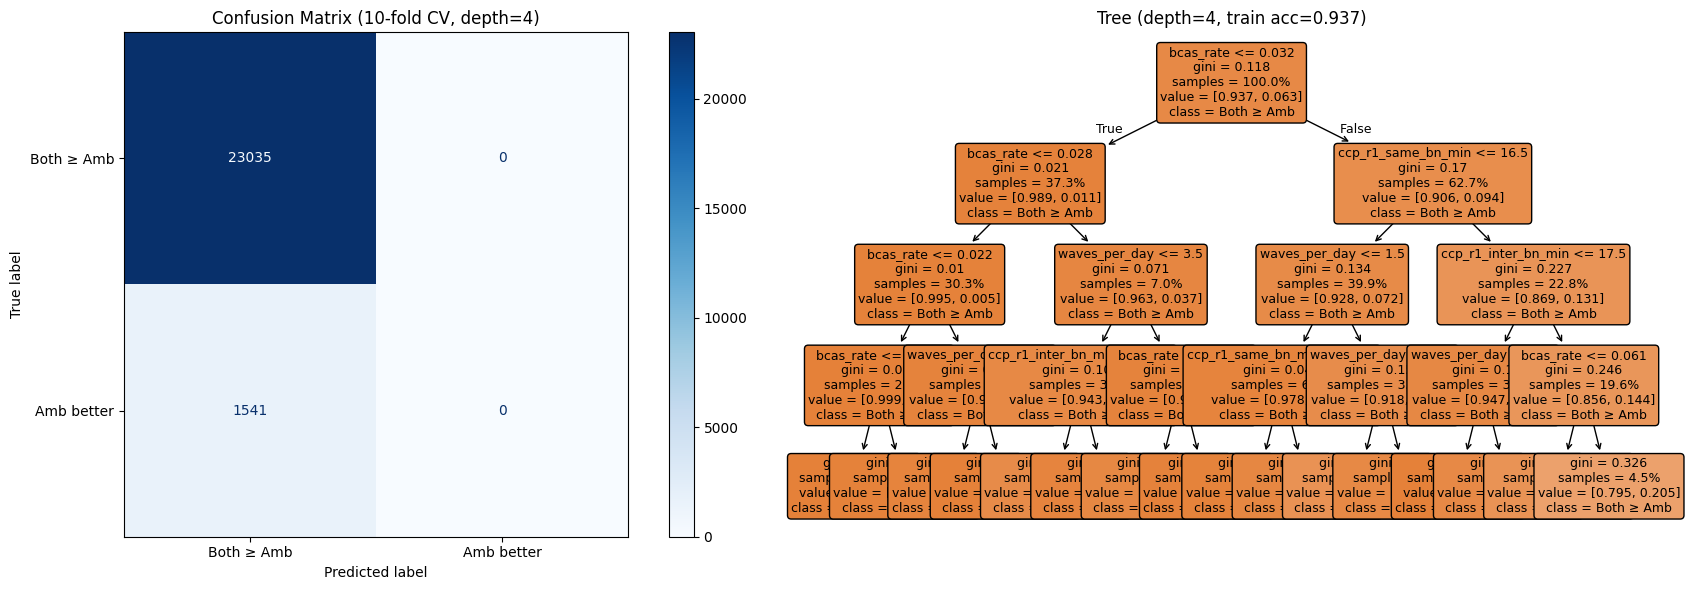

Feature importance:
bcas_rate             0.5836
waves_per_day         0.1837
ccp_r1_same_bn_min    0.1560
ccp_r1_inter_bn_min   0.0767
wave_duration_min     0.0000



In [9]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Target: both is worse than amb alone (delta > 0.01)
delta_both_vs_amb = m["mort_both"].values - m["mort_amb"].values
y_amb_better = (delta_both_vs_amb > 0.01).astype(int)

print(f"Amb alone better than both: {y_amb_better.sum()} / {len(y_amb_better)} ({y_amb_better.mean():.1%})")
print(f"Both better or equal: {(y_amb_better == 0).sum()} ({(y_amb_better == 0).mean():.1%})")

X = m[UNCERTAINTIES].astype(float)

for depth in [3, 4]:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=42)

    # Cross-validation
    cv_scores = cross_val_score(tree, X, y_amb_better, cv=10, scoring="accuracy")
    y_pred_cv = cross_val_predict(tree, X, y_amb_better, cv=10)
    print(f"\n{'='*60}")
    print(f"Decision Tree depth={depth}")
    print(f"{'='*60}")
    print(f"CV accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
    print(f"\nClassification report:")
    print(classification_report(y_amb_better, y_pred_cv, target_names=["Both ≥ Amb", "Amb better"]))

    # Confusion matrix
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    cm = confusion_matrix(y_amb_better, y_pred_cv)
    ConfusionMatrixDisplay(cm, display_labels=["Both ≥ Amb", "Amb better"]).plot(ax=axes[0], cmap="Blues")
    axes[0].set_title(f"Confusion Matrix (10-fold CV, depth={depth})")

    # Fit on full data for visualization
    tree.fit(X, y_amb_better)
    plot_tree(tree, feature_names=UNCERTAINTIES, class_names=["Both ≥ Amb", "Amb better"],
              filled=True, rounded=True, fontsize=9, ax=axes[1], proportion=True)
    axes[1].set_title(f"Tree (depth={depth}, train acc={tree.score(X, y_amb_better):.3f})")

    plt.tight_layout()
    plt.show()

    # Feature importance
    imp = pd.Series(tree.feature_importances_, index=UNCERTAINTIES).sort_values(ascending=False)
    print(f"Feature importance:")
    print(imp.to_string(float_format="%.4f"))
    print()

## Box Comparison — Inside the "both" PRIM box, how do policies compare?

Filter to scenarios inside the "both pooling" mortality box (bcas ≥ 0.034, waves ≤ 3.5, wave_dur ≤ 35.5, distance ≥ 16.5) with waves_per_day = 2, and compare nonzero mortality fraction across stovepipe, amb, and both.

Scenarios inside 'both' PRIM box: 1583
Scenarios inside box with waves=2: 517

Stovepipe:
  Nonzero mortality: 517 / 517 (100.0%)
  Mean mortality: 0.7560
  Median mortality: 0.7895

Amb only:
  Nonzero mortality: 509 / 517 (98.5%)
  Mean mortality: 0.4621
  Median mortality: 0.5000

Fac only:
  Nonzero mortality: 517 / 517 (100.0%)
  Mean mortality: 0.7567
  Median mortality: 0.7895

Both:
  Nonzero mortality: 490 / 517 (94.8%)
  Mean mortality: 0.4161
  Median mortality: 0.4444


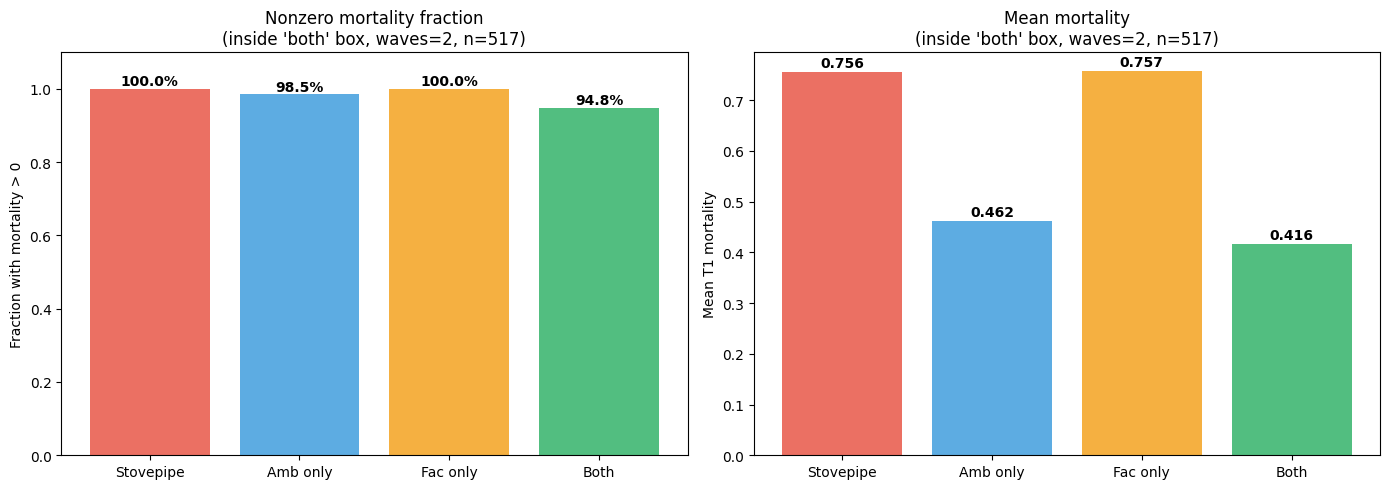


Full box (all wave counts):
  Stovepipe: nonzero 1583/1583 (100.0%), mean=0.7642
  Amb only: nonzero 1565/1583 (98.9%), mean=0.4479
  Fac only: nonzero 1583/1583 (100.0%), mean=0.7642
  Both: nonzero 1535/1583 (97.0%), mean=0.3991


In [10]:
# ── Filter to "both" PRIM box with waves_per_day = 2 ─────────────────────────
box_mask = (
    (m["bcas_rate"] >= 0.034) &
    (m["waves_per_day"] <= 3.5) &
    (m["wave_duration_min"] <= 35.5) &
    (m["ccp_r1_same_bn_min"] >= 16.5)
)
waves2_mask = box_mask & (m["waves_per_day"] == 2)

print(f"Scenarios inside 'both' PRIM box: {box_mask.sum()}")
print(f"Scenarios inside box with waves=2: {waves2_mask.sum()}")

sub = m[waves2_mask]

if len(sub) > 0:
    for policy, col in [("Stovepipe", "mort_stove"), ("Amb only", "mort_amb"), ("Fac only", "mort_fac"), ("Both", "mort_both")]:
        nonzero = (sub[col] > 0).sum()
        print(f"\n{policy}:")
        print(f"  Nonzero mortality: {nonzero} / {len(sub)} ({nonzero/len(sub):.1%})")
        print(f"  Mean mortality: {sub[col].mean():.4f}")
        print(f"  Median mortality: {sub[col].median():.4f}")

    # Bar chart comparing nonzero fractions
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    policies = ["Stovepipe", "Amb only", "Fac only", "Both"]
    cols = ["mort_stove", "mort_amb", "mort_fac", "mort_both"]
    colors = ["#e74c3c", "#3498db", "#f39c12", "#27ae60"]

    # Nonzero fraction
    fracs = [(sub[c] > 0).mean() for c in cols]
    bars = axes[0].bar(policies, fracs, color=colors, alpha=0.8)
    for bar, frac in zip(bars, fracs):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                     f"{frac:.1%}", ha="center", fontweight="bold")
    axes[0].set_ylabel("Fraction with mortality > 0")
    axes[0].set_title(f"Nonzero mortality fraction\n(inside 'both' box, waves=2, n={len(sub)})")
    axes[0].set_ylim(0, 1.1)

    # Mean mortality
    means = [sub[c].mean() for c in cols]
    bars = axes[1].bar(policies, means, color=colors, alpha=0.8)
    for bar, mean in zip(bars, means):
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                     f"{mean:.3f}", ha="center", fontweight="bold")
    axes[1].set_ylabel("Mean T1 mortality")
    axes[1].set_title(f"Mean mortality\n(inside 'both' box, waves=2, n={len(sub)})")

    plt.tight_layout()
    plt.show()
else:
    print("No scenarios match the filter.")

# ── Also show the full box (all wave counts) ─────────────────────────────────
print(f"\n{'='*60}")
print("Full box (all wave counts):")
sub_full = m[box_mask]
for policy, col in [("Stovepipe", "mort_stove"), ("Amb only", "mort_amb"), ("Fac only", "mort_fac"), ("Both", "mort_both")]:
    nonzero = (sub_full[col] > 0).sum()
    print(f"  {policy}: nonzero {nonzero}/{len(sub_full)} ({nonzero/len(sub_full):.1%}), mean={sub_full[col].mean():.4f}")